# Hierarchical Random Forest — EEG Artifact Classification

Leave-one-subject-out (LOSO) Random Forest pipeline operating on the handcrafted
feature matrix in `features.pkl`. Hierarchy:

1. **Stage 1** — artifact vs rest
2. **Stage 2** — ocular vs head/muscle
3. **Stage 3a / 3b** — fine label within each coarse group

A flat 7-class RF and a chained end-to-end pipeline are evaluated alongside the
thresholding baseline from `02_Thresholding.ipynb`.

## Section 1 — Imports & configuration

In [1]:
import pickle
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix, classification_report,
    precision_recall_fscore_support, roc_auc_score,
)

CONFIG = {
    "DATA_DIR": Path("processed_xdf"),
    "OUTPUT_DIR": Path("processed_xdf/03_RandomForest_plots"),
    "RANDOM_STATE": 42,
    "N_ESTIMATORS": 500,
    # Thresholding baseline results (from 02_Thresholding.ipynb) for comparison.
    "THRESHOLDING_ACC": 0.7759,
    "THRESHOLDING_F1":  0.7706,
}

RF_KWARGS = dict(
    n_estimators=CONFIG["N_ESTIMATORS"],
    class_weight="balanced",
    random_state=CONFIG["RANDOM_STATE"],
    n_jobs=-1,
)

# Exact label sets each stage is allowed to see and predict.
STAGE2_LABELS  = ("ocular", "head_muscle")
STAGE3A_LABELS = ("blink", "look_left", "look_right")
STAGE3B_LABELS = ("horiz_head", "vert_head", "clench")

CONFIG["OUTPUT_DIR"].mkdir(parents=True, exist_ok=True)
CONFIG["DATA_DIR"].mkdir(parents=True, exist_ok=True)
sns.set_context("notebook")
print("Configuration ready.")

Configuration ready.


## Section 2 — Load data & LOSO setup

In [2]:
# Load the handcrafted feature matrix (RF uses features only — no raw windows).
features_path = CONFIG["DATA_DIR"] / "features.pkl"
print(f"Loading {features_path}")
with features_path.open("rb") as f:
    bundle = pickle.load(f)

X             = bundle["X"]
y_fine        = bundle["y_fine"]
y_level1      = bundle["y_level1"]
y_level2      = bundle["y_level2"]
subject_ids   = bundle["subject_ids"]
feature_names = bundle["feature_names"]

# Replace None in y_level2 with the sentinel string 'none' so it can be used as
# a plain string array for filtering.
y_level2_for_enc = np.array(
    [lbl if lbl is not None else "none" for lbl in y_level2], dtype=object)

print(f"X.shape         : {X.shape}")
print(f"feature_names   : {len(feature_names)} entries")
print(f"unique subjects : {len(np.unique(subject_ids))}")


def _class_distribution_table(
    labels: np.ndarray, subjects: np.ndarray, title: str,
) -> None:
    """Print the overall and per-subject distribution for a label array."""
    print(f"\n=== {title} ===")
    overall = pd.Series(labels).value_counts(dropna=False)
    pct = (overall / overall.sum() * 100).round(1)
    print("Overall:")
    print(pd.DataFrame({"count": overall, "pct": pct}).to_string())

    per_subj = (
        pd.DataFrame({"subject_id": subjects, "label": labels})
        .assign(count=1)
        .pivot_table(index="subject_id", columns="label",
                     values="count", aggfunc="sum", fill_value=0)
    )
    per_subj["TOTAL"] = per_subj.sum(axis=1)
    print("\nPer subject:")
    print(per_subj.to_string())


_class_distribution_table(y_level1, subject_ids, "Level 1 (artifact / rest)")
_class_distribution_table(y_level2_for_enc, subject_ids,
                          "Level 2 (ocular / head_muscle / none)")
_class_distribution_table(y_fine, subject_ids, "Fine label")

Loading processed_xdf\features.pkl
X.shape         : (11418, 324)
feature_names   : 324 entries
unique subjects : 13

=== Level 1 (artifact / rest) ===
Overall:
          count   pct
artifact   5907  51.7
rest       5511  48.3

Per subject:
label         artifact  rest  TOTAL
subject_id                         
sub-0b11bec3       456   424    880
sub-123051bf       457   424    881
sub-160f8068       456   424    880
sub-2cbce981       438   424    862
sub-3f0ec71e       450   420    870
sub-413e6462       456   424    880
sub-81091e67       457   424    881
sub-9c5349dc       456   425    881
sub-b835837a       456   424    880
sub-bf3d1a74       456   424    880
sub-d0bb067d       457   424    881
sub-ece8d790       456   425    881
sub-f415eee8       456   425    881

=== Level 2 (ocular / head_muscle / none) ===
Overall:
             count   pct
none          5511  48.3
ocular        2963  26.0
head_muscle   2944  25.8

Per subject:
label         head_muscle  none  ocular  TOTAL
su

In [3]:
# LOSO folds — one fold per subject.
LOSO_SUBJECTS = sorted(np.unique(subject_ids))
print(f"LOSO folds ({len(LOSO_SUBJECTS)}): {LOSO_SUBJECTS}")


def loso_fold(test_subject: str) -> tuple[np.ndarray, np.ndarray]:
    """Return (train_idx, test_idx) row indices for one leave-one-subject-out fold."""
    test_idx  = np.where(subject_ids == test_subject)[0]
    train_idx = np.where(subject_ids != test_subject)[0]
    return train_idx, test_idx

LOSO folds (13): ['sub-0b11bec3', 'sub-123051bf', 'sub-160f8068', 'sub-2cbce981', 'sub-3f0ec71e', 'sub-413e6462', 'sub-81091e67', 'sub-9c5349dc', 'sub-b835837a', 'sub-bf3d1a74', 'sub-d0bb067d', 'sub-ece8d790', 'sub-f415eee8']


## Section 3 — Helper functions

In [4]:
# Random generator shared by the downsampler — fixed for reproducibility.
RNG = np.random.default_rng(CONFIG["RANDOM_STATE"])


def balanced_train_indices(train_idx: np.ndarray) -> np.ndarray:
    """Downsample rest windows in a training fold to match the artifact count.

    Parameters
    ----------
    train_idx : numpy.ndarray
        Indices into the global feature matrix for the training fold.

    Returns
    -------
    numpy.ndarray
        Subset of ``train_idx`` containing all artifact windows + an equal-sized
        random sample of rest windows (the same random state across folds gives
        reproducibility).
    """
    fold_l1 = y_level1[train_idx]
    artifact_local = np.where(fold_l1 == "artifact")[0]
    rest_local     = np.where(fold_l1 == "rest")[0]

    n_artifact = len(artifact_local)
    n_rest_keep = min(n_artifact, len(rest_local))

    rest_sample = RNG.choice(rest_local, size=n_rest_keep, replace=False)
    balanced_local = np.concatenate([artifact_local, rest_sample])
    return train_idx[balanced_local]


def plot_confusion(
    cm: np.ndarray, labels: list[str], title: str, cmap: str,
    fname: str, normalise: bool = True,
) -> None:
    """Plot and save a confusion-matrix heatmap.

    Parameters
    ----------
    cm : numpy.ndarray
        Confusion matrix from ``sklearn.metrics.confusion_matrix``.
    labels : list of str
        Class names, in the same order as the rows/columns of ``cm``.
    title : str
        Plot title.
    cmap : str
        Seaborn/matplotlib colormap name.
    fname : str
        Output file name, saved under ``CONFIG['OUTPUT_DIR']``.
    normalise : bool, default True
        If True, divide each row by its sum so cells show per-class recall.
    """
    if normalise:
        row_sums = cm.sum(axis=1, keepdims=True)
        data = cm / np.clip(row_sums, 1, None)
        fmt = ".2f"
    else:
        data = cm
        fmt = "d"

    fig, ax = plt.subplots(figsize=(0.9 * len(labels) + 2.5,
                                    0.8 * len(labels) + 2))
    sns.heatmap(data, annot=True, fmt=fmt, cmap=cmap,
                xticklabels=labels, yticklabels=labels,
                vmin=0 if normalise else None,
                vmax=1 if normalise else None, ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=40)
    fig.tight_layout()
    fig.savefig(CONFIG["OUTPUT_DIR"] / fname, dpi=140)
    plt.show()

## Section 4 — LOSO training loop

Trains the four per-stage Random Forests + a flat 7-class RF on every fold, and
runs chained inference (Stage 1 → 2 → 3a/3b) per test window. Downsampling and
the scaler are fit on the training fold only — no leakage across subjects.

In [5]:
# Accumulators for predictions and per-fold importances.
fold_results: list[dict] = []
true_fine_all:    list[str] = []
pred_chain_all:   list[str] = []
pred_flat_all:    list[str] = []
pred_stage1_all:  list[str] = []          # binary
pred_stage1_prob_all: list[float] = []     # P(artifact)

# Stage-specific accumulators — populated only with windows that pass each
# stage's true-label filter (no spurious extra classes).
true_stage2_all:  list[str] = []
pred_stage2_all:  list[str] = []
true_stage3a_all: list[str] = []
pred_stage3a_all: list[str] = []
true_stage3b_all: list[str] = []
pred_stage3b_all: list[str] = []

stage_importances = defaultdict(list)      # stage → list of (n_features,) arrays
stage_f1_per_subject = defaultdict(dict)   # stage → {subject: f1}

print(f"Running LOSO-CV across {len(LOSO_SUBJECTS)} subjects...")

for fi, test_subject in enumerate(LOSO_SUBJECTS, 1):
    train_idx, test_idx = loso_fold(test_subject)
    bal_idx = balanced_train_indices(train_idx)

    X_train_bal = X[bal_idx]
    X_test      = X[test_idx]

    # Standard scaler — fitted but not applied to RF (kept for future use).
    _scaler = StandardScaler().fit(X_train_bal)

    # ---- Stage 1: artifact vs rest ----
    y_train_s1 = y_level1[bal_idx]
    y_test_s1  = y_level1[test_idx]
    rf_s1 = RandomForestClassifier(**RF_KWARGS)
    rf_s1.fit(X_train_bal, y_train_s1)
    s1_pred = rf_s1.predict(X_test)
    s1_proba = rf_s1.predict_proba(X_test)
    s1_classes = list(rf_s1.classes_)
    s1_artifact_col = s1_classes.index("artifact")
    s1_prob_artifact = s1_proba[:, s1_artifact_col]
    stage_importances["stage1"].append(rf_s1.feature_importances_)

    # ---- Stage 2: ocular vs head_muscle (filtered to exactly 2 classes) ----
    bal_s2_mask = np.isin(y_level2_for_enc[bal_idx], STAGE2_LABELS)
    X_train_s2 = X[bal_idx][bal_s2_mask]
    y_train_s2 = y_level2_for_enc[bal_idx][bal_s2_mask]
    rf_s2 = RandomForestClassifier(**RF_KWARGS)
    rf_s2.fit(X_train_s2, y_train_s2)
    stage_importances["stage2"].append(rf_s2.feature_importances_)

    # Test subset: windows whose TRUE level-2 is exactly ocular/head_muscle.
    s2_test_mask = np.isin(y_level2_for_enc[test_idx], STAGE2_LABELS)
    if s2_test_mask.any():
        X_test_s2 = X_test[s2_test_mask]
        y_true_s2 = y_level2_for_enc[test_idx][s2_test_mask]
        s2_pred_direct = rf_s2.predict(X_test_s2)
    else:
        y_true_s2 = np.empty(0, dtype=object)
        s2_pred_direct = np.empty(0, dtype=object)

    # ---- Stage 3a: fine ocular (filtered to exactly 3 classes) ----
    bal_s3a_mask = np.isin(y_fine[bal_idx], STAGE3A_LABELS)
    X_train_s3a = X[bal_idx][bal_s3a_mask]
    y_train_s3a = y_fine[bal_idx][bal_s3a_mask]
    rf_s3a = RandomForestClassifier(**RF_KWARGS)
    rf_s3a.fit(X_train_s3a, y_train_s3a)
    stage_importances["stage3a"].append(rf_s3a.feature_importances_)

    s3a_test_mask = np.isin(y_fine[test_idx], STAGE3A_LABELS)
    if s3a_test_mask.any():
        X_test_s3a = X_test[s3a_test_mask]
        y_true_s3a = y_fine[test_idx][s3a_test_mask]
        s3a_pred_direct = rf_s3a.predict(X_test_s3a)
    else:
        y_true_s3a = np.empty(0, dtype=object)
        s3a_pred_direct = np.empty(0, dtype=object)

    # ---- Stage 3b: fine head/muscle (filtered to exactly 3 classes) ----
    bal_s3b_mask = np.isin(y_fine[bal_idx], STAGE3B_LABELS)
    X_train_s3b = X[bal_idx][bal_s3b_mask]
    y_train_s3b = y_fine[bal_idx][bal_s3b_mask]
    rf_s3b = RandomForestClassifier(**RF_KWARGS)
    rf_s3b.fit(X_train_s3b, y_train_s3b)
    stage_importances["stage3b"].append(rf_s3b.feature_importances_)

    s3b_test_mask = np.isin(y_fine[test_idx], STAGE3B_LABELS)
    if s3b_test_mask.any():
        X_test_s3b = X_test[s3b_test_mask]
        y_true_s3b = y_fine[test_idx][s3b_test_mask]
        s3b_pred_direct = rf_s3b.predict(X_test_s3b)
    else:
        y_true_s3b = np.empty(0, dtype=object)
        s3b_pred_direct = np.empty(0, dtype=object)

    # ---- Flat RF baseline ----
    rf_flat = RandomForestClassifier(**RF_KWARGS)
    rf_flat.fit(X_train_bal, y_fine[bal_idx])
    pred_flat = rf_flat.predict(X_test)
    stage_importances["flat"].append(rf_flat.feature_importances_)

    # ---- Chained inference per test window ----
    chain_pred = np.empty(len(test_idx), dtype=object)
    for i in range(len(test_idx)):
        if s1_pred[i] == "rest":
            chain_pred[i] = "rest"
            continue
        # Predict coarse group
        s2_pred = rf_s2.predict(X_test[[i]])[0]
        if s2_pred == "ocular":
            chain_pred[i] = rf_s3a.predict(X_test[[i]])[0]
        elif s2_pred == "head_muscle":
            chain_pred[i] = rf_s3b.predict(X_test[[i]])[0]
        else:
            chain_pred[i] = "unknown_artifact"

    # Per-fold metric (Stage 1 F1 macro — used in Section 12).
    fold_f1_s1 = f1_score(y_test_s1, s1_pred, average="macro")
    fold_acc_s1 = accuracy_score(y_test_s1, s1_pred)
    stage_f1_per_subject["stage1"][test_subject] = fold_f1_s1

    fold_results.append({
        "subject":   test_subject,
        "n_test":    int(len(test_idx)),
        "n_train_balanced": int(len(bal_idx)),
        "stage1_f1": fold_f1_s1,
        "stage1_acc": fold_acc_s1,
        "stage1_proba_artifact": s1_prob_artifact,
        "stage1_pred": s1_pred,
        "stage1_true": y_test_s1,
        "chain_pred": chain_pred,
        "flat_pred": pred_flat,
        "test_idx":  test_idx,
    })

    true_fine_all.extend(y_fine[test_idx].tolist())
    pred_chain_all.extend(chain_pred.tolist())
    pred_flat_all.extend(pred_flat.tolist())
    pred_stage1_all.extend(s1_pred.tolist())
    pred_stage1_prob_all.extend(s1_prob_artifact.tolist())

    true_stage2_all.extend(y_true_s2.tolist())
    pred_stage2_all.extend(s2_pred_direct.tolist())
    true_stage3a_all.extend(y_true_s3a.tolist())
    pred_stage3a_all.extend(s3a_pred_direct.tolist())
    true_stage3b_all.extend(y_true_s3b.tolist())
    pred_stage3b_all.extend(s3b_pred_direct.tolist())

    print(f"  fold {fi}/{len(LOSO_SUBJECTS)}  subject={test_subject:>16s}  "
          f"n_test={len(test_idx):4d}  stage1_f1={fold_f1_s1:.3f}")

true_fine_all    = np.asarray(true_fine_all)
pred_chain_all   = np.asarray(pred_chain_all)
pred_flat_all    = np.asarray(pred_flat_all)
pred_stage1_all  = np.asarray(pred_stage1_all)
pred_stage1_prob_all = np.asarray(pred_stage1_prob_all)

true_stage2_all  = np.asarray(true_stage2_all,  dtype=object)
pred_stage2_all  = np.asarray(pred_stage2_all,  dtype=object)
true_stage3a_all = np.asarray(true_stage3a_all, dtype=object)
pred_stage3a_all = np.asarray(pred_stage3a_all, dtype=object)
true_stage3b_all = np.asarray(true_stage3b_all, dtype=object)
pred_stage3b_all = np.asarray(pred_stage3b_all, dtype=object)

print("\nLOSO loop complete.")

Running LOSO-CV across 13 subjects...
  fold 1/13  subject=    sub-0b11bec3  n_test= 880  stage1_f1=0.857
  fold 2/13  subject=    sub-123051bf  n_test= 881  stage1_f1=0.983
  fold 3/13  subject=    sub-160f8068  n_test= 880  stage1_f1=0.926
  fold 4/13  subject=    sub-2cbce981  n_test= 862  stage1_f1=0.846
  fold 5/13  subject=    sub-3f0ec71e  n_test= 870  stage1_f1=0.869
  fold 6/13  subject=    sub-413e6462  n_test= 880  stage1_f1=0.868
  fold 7/13  subject=    sub-81091e67  n_test= 881  stage1_f1=0.917
  fold 8/13  subject=    sub-9c5349dc  n_test= 881  stage1_f1=0.913
  fold 9/13  subject=    sub-b835837a  n_test= 880  stage1_f1=0.903
  fold 10/13  subject=    sub-bf3d1a74  n_test= 880  stage1_f1=0.703
  fold 11/13  subject=    sub-d0bb067d  n_test= 881  stage1_f1=0.882
  fold 12/13  subject=    sub-ece8d790  n_test= 881  stage1_f1=0.916
  fold 13/13  subject=    sub-f415eee8  n_test= 881  stage1_f1=0.916

LOSO loop complete.


## Section 5 — Per-stage evaluation

Stage 1 (artifact vs rest) — LOSO aggregate
  Accuracy : 0.8850
  F1 macro : 0.8849
  ROC-AUC  : 0.9520
              precision    recall  f1-score   support

        rest      0.876     0.888     0.882      5511
    artifact      0.894     0.882     0.888      5907

    accuracy                          0.885     11418
   macro avg      0.885     0.885     0.885     11418
weighted avg      0.885     0.885     0.885     11418



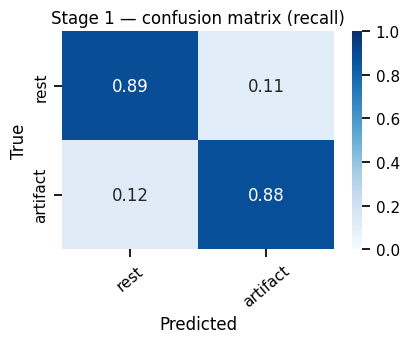

In [6]:
# ---- Stage 1: artifact vs rest ----
true_l1_all = np.array(["rest" if t == "rest" else "artifact" for t in true_fine_all])

s1_acc = accuracy_score(true_l1_all, pred_stage1_all)
s1_f1  = f1_score(true_l1_all, pred_stage1_all, average="macro")
y_true_bin = (true_l1_all == "artifact").astype(int)
s1_auc = roc_auc_score(y_true_bin, pred_stage1_prob_all)

print("Stage 1 (artifact vs rest) — LOSO aggregate")
print(f"  Accuracy : {s1_acc:.4f}")
print(f"  F1 macro : {s1_f1:.4f}")
print(f"  ROC-AUC  : {s1_auc:.4f}")
print(classification_report(true_l1_all, pred_stage1_all,
                            labels=["rest", "artifact"], digits=3))

s1_cm = confusion_matrix(true_l1_all, pred_stage1_all, labels=["rest", "artifact"])
plot_confusion(s1_cm, ["rest", "artifact"],
               "Stage 1 — confusion matrix (recall)",
               "Blues", "stage1_confusion.png", normalise=True)

Stage 2 (ocular vs head_muscle) — pooled across folds
  n test windows : 5907
  Accuracy       : 0.9309
  F1 macro       : 0.9309
              precision    recall  f1-score   support

      ocular      0.924     0.940     0.932      2963
 head_muscle      0.938     0.922     0.930      2944

    accuracy                          0.931      5907
   macro avg      0.931     0.931     0.931      5907
weighted avg      0.931     0.931     0.931      5907



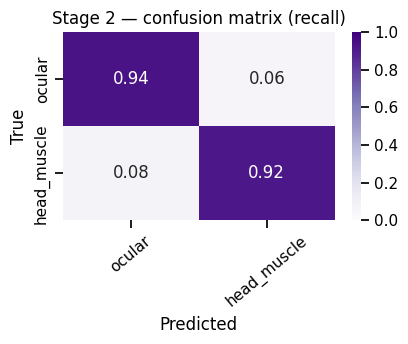

In [7]:
# ---- Stage 2: ocular vs head_muscle (pooled over true-label test windows) ----
s2_labels = list(STAGE2_LABELS)
s2_acc = accuracy_score(true_stage2_all, pred_stage2_all)
s2_f1  = f1_score(true_stage2_all, pred_stage2_all, average="macro",
                  labels=s2_labels, zero_division=0)

print("Stage 2 (ocular vs head_muscle) — pooled across folds")
print(f"  n test windows : {len(true_stage2_all)}")
print(f"  Accuracy       : {s2_acc:.4f}")
print(f"  F1 macro       : {s2_f1:.4f}")
print(classification_report(true_stage2_all, pred_stage2_all,
                            labels=s2_labels, digits=3, zero_division=0))

s2_cm = confusion_matrix(true_stage2_all, pred_stage2_all, labels=s2_labels)
plot_confusion(s2_cm, s2_labels, "Stage 2 — confusion matrix (recall)",
               "Purples", "stage2_confusion.png", normalise=True)


Stage 3a (fine ocular) — pooled across folds
  n test windows : 2963
  Accuracy       : 0.7843
  F1 macro       : 0.7844
              precision    recall  f1-score   support

       blink      0.766     0.773     0.769       988
   look_left      0.784     0.783     0.784       988
  look_right      0.804     0.796     0.800       987

    accuracy                          0.784      2963
   macro avg      0.784     0.784     0.784      2963
weighted avg      0.784     0.784     0.784      2963



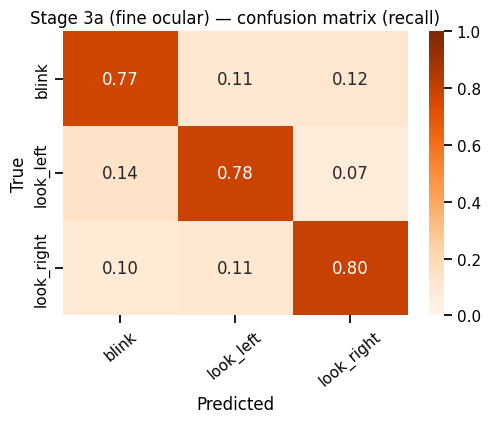


Stage 3b (fine head/muscle) — pooled across folds
  n test windows : 2944
  Accuracy       : 0.6410
  F1 macro       : 0.6394
              precision    recall  f1-score   support

      clench      0.673     0.580     0.623       970
  horiz_head      0.677     0.751     0.712       987
   vert_head      0.575     0.591     0.583       987

    accuracy                          0.641      2944
   macro avg      0.642     0.641     0.639      2944
weighted avg      0.642     0.641     0.640      2944



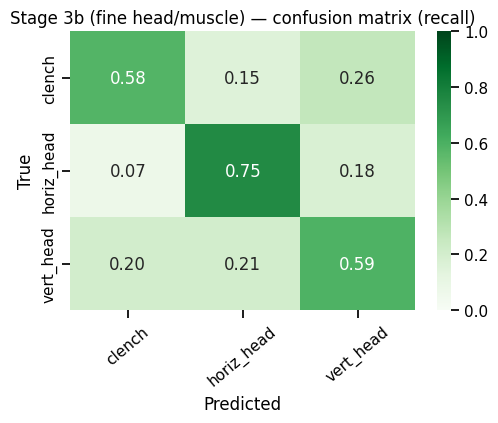

In [8]:
# ---- Stage 3a and 3b: fine label within each coarse group ----
def _evaluate_stage(
    y_true: np.ndarray, y_pred: np.ndarray, labels_sorted: list[str],
    title: str, cmap: str, fname: str,
) -> tuple[float, float]:
    """Print metrics + confusion matrix for one fine-grained stage; return (acc, f1)."""
    if len(y_true) == 0:
        print(f"{title}: no test windows in this subset.")
        return float("nan"), float("nan")
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average="macro",
                   labels=labels_sorted, zero_division=0)
    print(f"\n{title} — pooled across folds")
    print(f"  n test windows : {len(y_true)}")
    print(f"  Accuracy       : {acc:.4f}")
    print(f"  F1 macro       : {f1m:.4f}")
    print(classification_report(y_true, y_pred, labels=labels_sorted,
                                digits=3, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=labels_sorted)
    plot_confusion(cm, labels_sorted, f"{title} — confusion matrix (recall)",
                   cmap, fname, normalise=True)
    return acc, f1m


s3a_acc, s3a_f1 = _evaluate_stage(
    true_stage3a_all, pred_stage3a_all, sorted(STAGE3A_LABELS),
    "Stage 3a (fine ocular)", "Oranges", "stage3a_confusion.png")
s3b_acc, s3b_f1 = _evaluate_stage(
    true_stage3b_all, pred_stage3b_all, sorted(STAGE3B_LABELS),
    "Stage 3b (fine head/muscle)", "Greens", "stage3b_confusion.png")

Flat RF       — accuracy 0.7219  F1 macro 0.6167
Chained chain — accuracy 0.7259  F1 macro 0.6196

Flat RF classification report:
              precision    recall  f1-score   support

       blink      0.408     0.288     0.338       988
      clench      0.598     0.561     0.579       970
  horiz_head      0.590     0.621     0.605       987
   look_left      0.732     0.700     0.716       988
  look_right      0.738     0.682     0.709       987
        rest      0.840     0.893     0.865      5511
   vert_head      0.489     0.522     0.505       987

    accuracy                          0.722     11418
   macro avg      0.628     0.610     0.617     11418
weighted avg      0.712     0.722     0.715     11418


Chained pipeline classification report:
              precision    recall  f1-score   support

       blink      0.364     0.304     0.331       988
      clench      0.606     0.573     0.589       970
  horiz_head      0.586     0.647     0.615       987
   look_left   

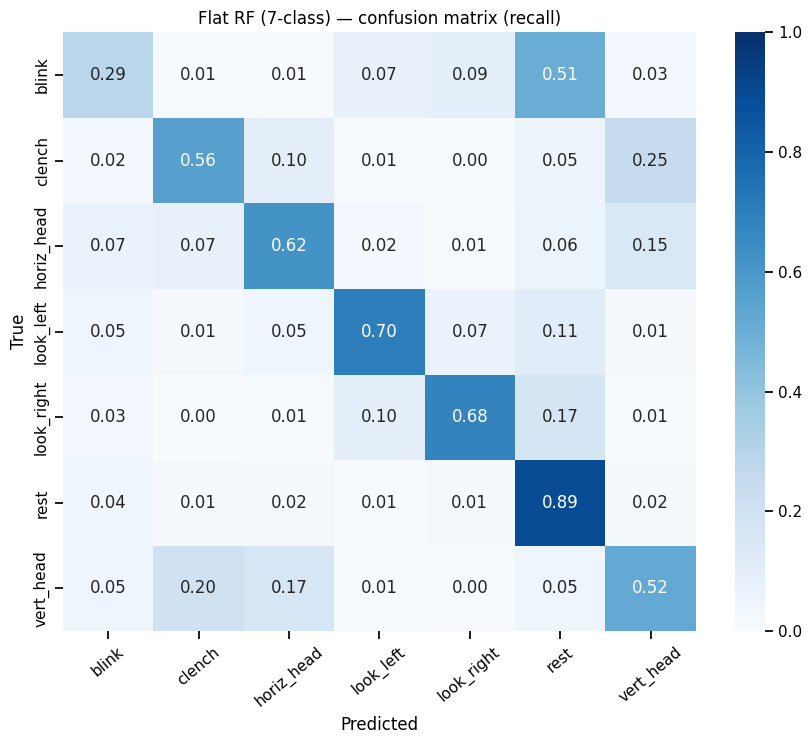

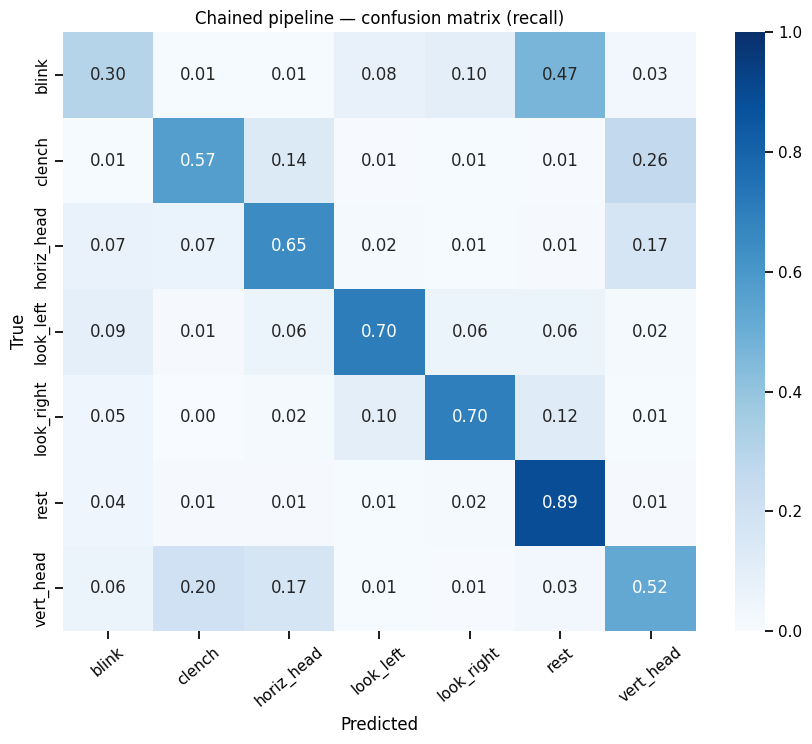

In [9]:
# ---- Flat RF baseline and chained pipeline, end-to-end (7-class) ----
all_fine_labels = sorted(set(true_fine_all.tolist()) | {"rest"})

flat_acc = accuracy_score(true_fine_all, pred_flat_all)
flat_f1  = f1_score(true_fine_all, pred_flat_all, average="macro",
                    labels=all_fine_labels, zero_division=0)
chain_acc = accuracy_score(true_fine_all, pred_chain_all)
chain_f1  = f1_score(true_fine_all, pred_chain_all, average="macro",
                     labels=all_fine_labels, zero_division=0)

print(f"Flat RF       — accuracy {flat_acc:.4f}  F1 macro {flat_f1:.4f}")
print(f"Chained chain — accuracy {chain_acc:.4f}  F1 macro {chain_f1:.4f}")

print("\nFlat RF classification report:")
print(classification_report(true_fine_all, pred_flat_all,
                            labels=all_fine_labels, digits=3, zero_division=0))
print("\nChained pipeline classification report:")
print(classification_report(true_fine_all, pred_chain_all,
                            labels=all_fine_labels, digits=3, zero_division=0))

flat_cm = confusion_matrix(true_fine_all, pred_flat_all, labels=all_fine_labels)
plot_confusion(flat_cm, all_fine_labels,
               "Flat RF (7-class) — confusion matrix (recall)",
               "Blues", "flat_confusion.png", normalise=True)

chain_cm = confusion_matrix(true_fine_all, pred_chain_all, labels=all_fine_labels)
plot_confusion(chain_cm, all_fine_labels,
               "Chained pipeline — confusion matrix (recall)",
               "Blues", "chained_confusion.png", normalise=True)

## Section 6 — Feature importance

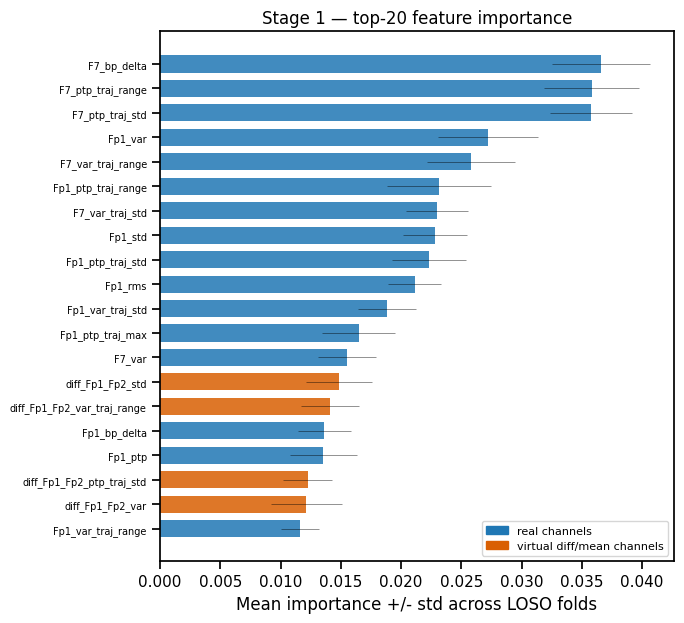

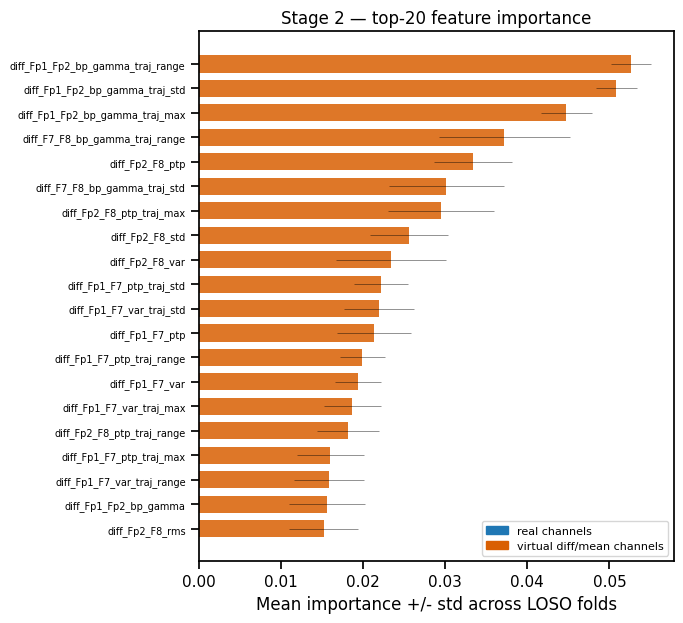

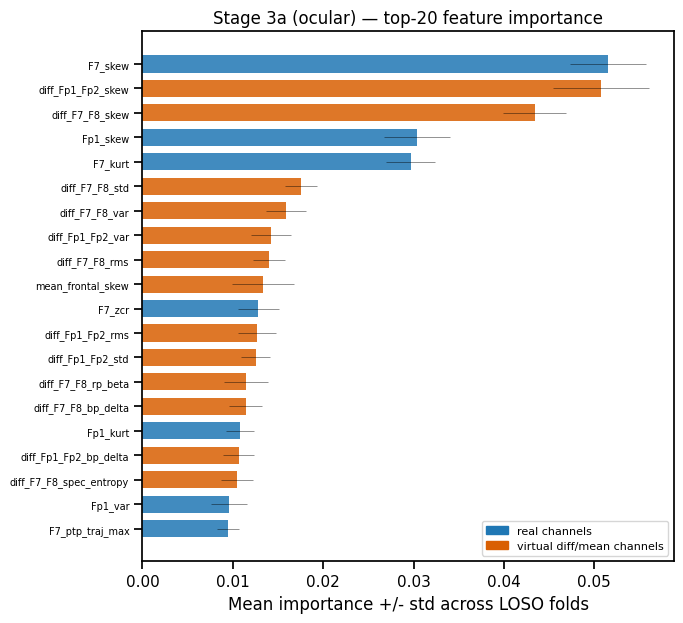

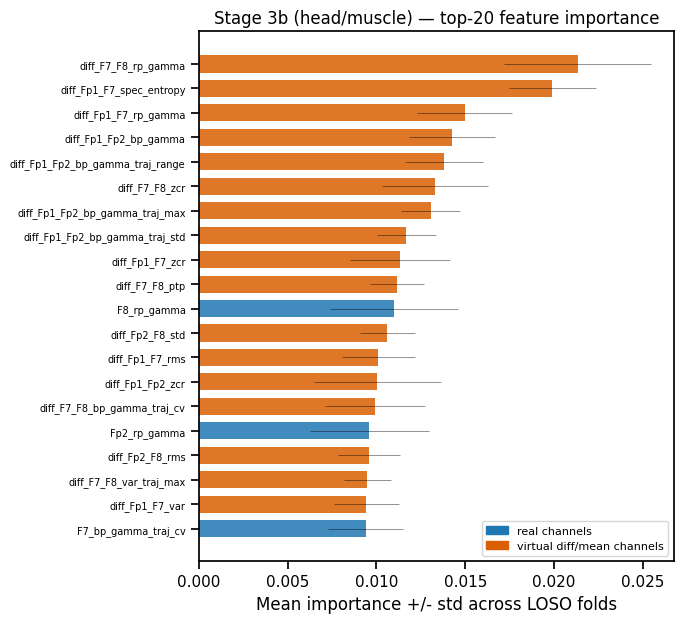

Virtual vs real channel importance share (sums to 1.0 per stage):
  Stage  Virtual share  Real share
 stage1          0.358       0.642
 stage2          0.838       0.162
stage3a          0.544       0.456
stage3b          0.663       0.337


In [10]:
# ---- Per-stage feature importance (aggregated across LOSO folds) ----
def _is_virtual(name: str) -> bool:
    """True if a feature comes from a virtual (diff / mean-frontal) channel."""
    return name.startswith("diff_") or name.startswith("mean_frontal")


def _plot_stage_importance(
    stage_key: str, title: str, fname: str, top_n: int = 20,
) -> pd.DataFrame:
    """Plot the top-N most important features for a stage; return the full ranking."""
    arr = np.vstack(stage_importances[stage_key])
    mean_imp = arr.mean(axis=0)
    std_imp  = arr.std(axis=0)

    ranking = pd.DataFrame({
        "feature": feature_names,
        "mean":    mean_imp,
        "std":     std_imp,
        "virtual": [_is_virtual(n) for n in feature_names],
    }).sort_values("mean", ascending=False).reset_index(drop=True)

    top = ranking.head(top_n).iloc[::-1]   # most important at the top of the bar chart
    colors = np.where(top["virtual"].to_numpy(), "#d95f02", "#1f77b4")

    fig, ax = plt.subplots(figsize=(7, max(4, 0.32 * top_n)))
    ax.barh(range(len(top)), top["mean"], xerr=top["std"], height=0.7,
            color=colors, alpha=0.85,
            error_kw={"elinewidth": 0.6, "alpha": 0.5})
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top["feature"], fontsize=7)
    ax.set_xlabel("Mean importance +/- std across LOSO folds")
    ax.set_title(title)
    legend = [
        mpatches.Patch(color="#1f77b4", label="real channels"),
        mpatches.Patch(color="#d95f02", label="virtual diff/mean channels"),
    ]
    ax.legend(handles=legend, loc="lower right", fontsize=8)
    fig.tight_layout()
    fig.savefig(CONFIG["OUTPUT_DIR"] / fname, dpi=140)
    plt.show()
    return ranking


fi_stage1  = _plot_stage_importance("stage1",
    "Stage 1 — top-20 feature importance", "feature_importance_stage1.png")
fi_stage2  = _plot_stage_importance("stage2",
    "Stage 2 — top-20 feature importance", "feature_importance_stage2.png")
fi_stage3a = _plot_stage_importance("stage3a",
    "Stage 3a (ocular) — top-20 feature importance", "feature_importance_stage3a.png")
fi_stage3b = _plot_stage_importance("stage3b",
    "Stage 3b (head/muscle) — top-20 feature importance", "feature_importance_stage3b.png")

# Virtual vs real channel importance share per stage.
share_rows = []
for key, fi in [("stage1", fi_stage1), ("stage2", fi_stage2),
                ("stage3a", fi_stage3a), ("stage3b", fi_stage3b)]:
    v = fi.loc[fi["virtual"], "mean"].sum()
    r = fi.loc[~fi["virtual"], "mean"].sum()
    share_rows.append({"Stage": key, "Virtual share": round(v, 3),
                       "Real share": round(r, 3)})
share_df = pd.DataFrame(share_rows)
print("Virtual vs real channel importance share (sums to 1.0 per stage):")
print(share_df.to_string(index=False))

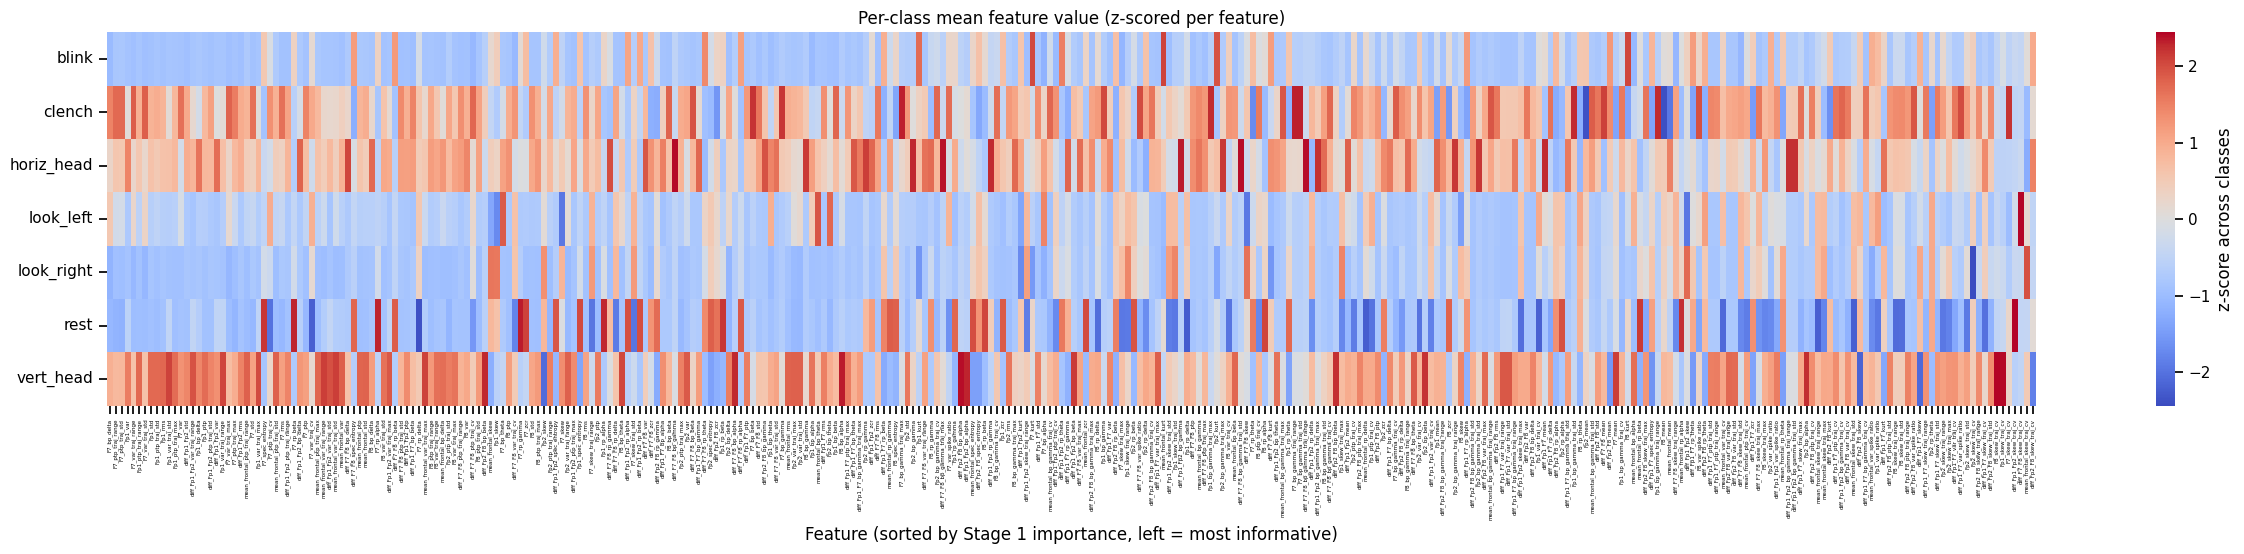

In [11]:
# ---- Per-class mean feature heatmap (descriptive only — affects no model) ----
fine_labels_for_heatmap = sorted(np.unique(y_fine).tolist())
per_class_means = np.vstack([
    X[y_fine == lbl].mean(axis=0) for lbl in fine_labels_for_heatmap
])

# Z-score each column (feature) so scales are comparable across features.
col_mean = per_class_means.mean(axis=0)
col_std  = per_class_means.std(axis=0) + 1e-12
zscored = (per_class_means - col_mean) / col_std

# Sort columns by Stage 1 mean importance (descending) so the most
# discriminative features appear on the left.
s1_mean_imp = np.vstack(stage_importances["stage1"]).mean(axis=0)
col_order = np.argsort(-s1_mean_imp)
zscored_sorted  = zscored[:, col_order]
features_sorted = [feature_names[i] for i in col_order]

fig, ax = plt.subplots(figsize=(min(28, 0.06 * len(features_sorted) + 6),
                                0.6 * len(fine_labels_for_heatmap) + 1.5))
sns.heatmap(zscored_sorted, cmap="coolwarm", center=0,
            xticklabels=features_sorted, yticklabels=fine_labels_for_heatmap,
            cbar_kws={"label": "z-score across classes"}, ax=ax)
ax.set_xlabel("Feature (sorted by Stage 1 importance, left = most informative)")
ax.set_title("Per-class mean feature value (z-scored per feature)")
ax.tick_params(axis="x", rotation=90, labelsize=4)
fig.tight_layout()
fig.savefig(CONFIG["OUTPUT_DIR"] / "per_class_feature_heatmap.png", dpi=160)
plt.show()

## Section 7 — Results summary

In [12]:
# ---- Model comparison (LOSO aggregate) ----
comparison_df = pd.DataFrame([
    {"model": "Thresholding (binary)",
     "accuracy": CONFIG["THRESHOLDING_ACC"], "f1_macro": CONFIG["THRESHOLDING_F1"],
     "notes": "binary only; rules fitted on training rest"},
    {"model": "Flat RF (7-class)",
     "accuracy": flat_acc, "f1_macro": flat_f1,
     "notes": "single RF, balanced train"},
    {"model": "Stage 1 only",
     "accuracy": s1_acc, "f1_macro": s1_f1,
     "notes": f"RF binary; ROC-AUC={s1_auc:.4f}"},
    {"model": "Stage 2",
     "accuracy": s2_acc, "f1_macro": s2_f1,
     "notes": "ocular vs head_muscle (true-label test windows)"},
    {"model": "Stage 3a (ocular)",
     "accuracy": s3a_acc, "f1_macro": s3a_f1,
     "notes": "blink / look_left / look_right"},
    {"model": "Stage 3b (head/musc)",
     "accuracy": s3b_acc, "f1_macro": s3b_f1,
     "notes": "horiz_head / vert_head / clench"},
    {"model": "Chained pipeline",
     "accuracy": chain_acc, "f1_macro": chain_f1,
     "notes": "Stage1 -> Stage2 -> Stage3a/3b"},
])
print(comparison_df.round(4).to_string(index=False))

                model  accuracy  f1_macro                                           notes
Thresholding (binary)    0.7759    0.7706      binary only; rules fitted on training rest
    Flat RF (7-class)    0.7219    0.6167                       single RF, balanced train
         Stage 1 only    0.8850    0.8849                       RF binary; ROC-AUC=0.9520
              Stage 2    0.9309    0.9309 ocular vs head_muscle (true-label test windows)
    Stage 3a (ocular)    0.7843    0.7844                  blink / look_left / look_right
 Stage 3b (head/musc)    0.6410    0.6394                 horiz_head / vert_head / clench
     Chained pipeline    0.7259    0.6196                  Stage1 -> Stage2 -> Stage3a/3b
